# Area Chart

**Family:** Change over time &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Basic

> *Change over time:* Emphasise changing trends, from intraday moves to series spanning decades.

## Design purpose

A line chart with the area below the line filled in. The fill stresses volume, the cumulative size of the quantity over time, not just its trend.

## When to use

- Show a single quantity whose magnitude (volume) matters, such as traffic, energy, or storage used
- Emphasise that values are counts or amounts accumulating from zero

## Avoid when

- Comparing several overlapping series (fills hide each other; use lines)
- The y-axis does not start at zero (a fill implies zero baseline)

## Alternatives

- Line chart
- Stacked area chart (several parts of a total)

## Design tips

- Always start the y-axis at zero
- Use a light fill plus a solid 2px line on top

## Example

Daily website visits over 6 months.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
pio.templates["vizlib"] = go.layout.Template(layout=dict(
    colorway=PALETTE, font=dict(family="Helvetica, Arial, sans-serif", size=13, color="#0b0b0b"),
    paper_bgcolor="#fcfcfb", plot_bgcolor="#fcfcfb", title=dict(x=0.02, xanchor="left"),
    xaxis=dict(gridcolor="#e6e5e1", linecolor="#c9c8c3", zeroline=False),
    yaxis=dict(gridcolor="#e6e5e1", linecolor="#c9c8c3", zeroline=False),
))
pio.templates.default = "plotly_white+vizlib"

import numpy as np
import pandas as pd
import altair as alt

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]


@alt.theme.register("vizlib", enable=True)
def vizlib_theme():
    return alt.theme.ThemeConfig({
        "config": {
            "background": "#fcfcfb",
            "view": {"stroke": None},
            "range": {"category": PALETTE},
            "font": "Helvetica, Arial, sans-serif",
            "title": {"anchor": "start", "fontSize": 14, "color": "#0b0b0b"},
            "axis": {"gridColor": "#e6e5e1", "domainColor": "#c9c8c3", "tickColor": "#c9c8c3",
                     "labelColor": "#52514e", "titleColor": "#52514e", "titleFontWeight": "normal"},
            "legend": {"labelColor": "#52514e", "titleColor": "#52514e"},
        }
    })
pio.renderers.default = "plotly_mimetype+notebook_connected"

### Data

In [2]:
rng = np.random.default_rng(4)
dates = pd.date_range("2024-01-01", periods=182, freq="D")
weekly = 1 + 0.25 * np.sin(2 * np.pi * dates.dayofweek / 7)
visits = (2000 + np.linspace(0, 1500, len(dates))) * weekly + rng.normal(0, 150, len(dates))
df = pd.DataFrame({"date": dates, "visits": visits.round()})
df.head()

,date,visits
0,2024-01-01,1902.0
1,2024-01-02,2375.0
2,2024-01-03,2758.0
3,2024-01-04,2343.0
4,2024-01-05,1566.0


### Plot

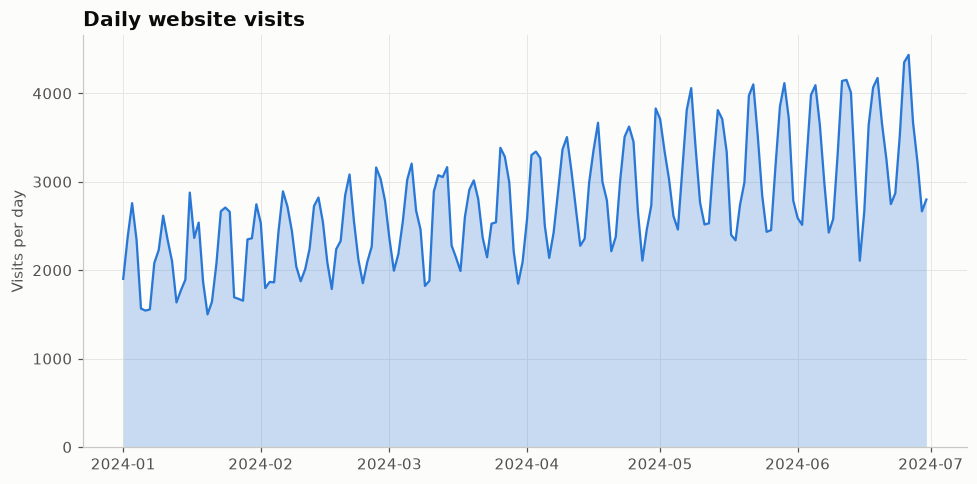

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.fill_between(df["date"], df["visits"], color=PALETTE[0], alpha=0.25, linewidth=0)
ax.plot(df["date"], df["visits"], color=PALETTE[0], linewidth=1.5)
ax.set_ylim(0, None)
ax.set_ylabel("Visits per day")
ax.set_title("Daily website visits")
fig.tight_layout()
plt.show()

## The same chart in other libraries

Each version uses the example data above. Pick the library that fits your stack: matplotlib/seaborn for static and print figures, plotly for interactive HTML, Altair for concise declarative specs.

### plotly

In [4]:
import plotly.express as px
fig = px.area(df, x="date", y="visits", color_discrete_sequence=PALETTE,
              labels={"date": "", "visits": "Visits per day"}, title="Daily website visits")
fig.update_traces(line_width=1.5)
fig.update_layout(hovermode="x unified")
fig.show()

### altair

In [5]:
import altair as alt
chart = alt.Chart(df).mark_area(line={"color": PALETTE[0]}, color=PALETTE[0], opacity=0.35).encode(
    x=alt.X("date:T", title=None), y=alt.Y("visits:Q", title="Visits per day"),
    tooltip=["date:T", "visits:Q"],
).properties(title="Daily website visits", width=560, height=280)
chart

alt.Chart(...)

---
Standalone script: [`area_chart.py`](area_chart.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)